# Particle in a 2D Circular Infinite Well — Probability Density

Potential: $V=0$ for $r<a$, $V=\infty$ otherwise. Separating $\psi(r,\theta)=R(r)\Theta(\theta)$ gives

$$\psi_{n,l}(r,\theta)=N_{n,l}\,J_l(k_{n,l}r)\,e^{il\theta},\qquad k_{n,l}=\frac{j_{l,n}}{a},\qquad E_{n,l}=\frac{\hbar^2k_{n,l}^2}{2m}$$

where $j_{l,n}$ is the $n$-th zero of $J_l$.

**Normalization.** Using $\int_0^a J_l^2(kr)\,r\,dr=\tfrac{a^2}{2}J_{l+1}^2(ka)$ when $J_l(ka)=0$:

$$|N_{n,l}|^2=\frac{1}{\pi a^2 J_{l+1}^2(j_{l,n})}$$

**Note on $\theta$-dependence.** Since $|e^{il\theta}|^2=1$, the density of an $L_z$ eigenstate is **circularly symmetric** — you see rings, not lobes. The states $\pm l$ are degenerate, so the combinations $\cos(l\theta)$ and $\sin(l\theta)$ are equally valid energy eigenstates (but not $L_z$ eigenstates); these show $2l$ angular lobes. Both options are provided below.

Energies are shown in units of $\hbar^2/(2ma^2)$, i.e. $E = j_{l,n}^2$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, jn_zeros
from matplotlib import cm

a = 1.0  # well radius

def bessel_zero(n, l):
    # n-th zero (n = 1, 2, ...) of J_l
    return jn_zeros(l, n)[-1]

def prob_density(n, l, mode="exp", Nr=120, Nt=180):
    # Return X, Y, |psi|^2 on a polar grid, plus the zero j_{l,n}.
    # mode: "exp" -> e^{il theta} (L_z eigenstate, ring-shaped)
    #       "cos" -> sqrt(2) cos(l theta)  (standing wave, 2l lobes)
    j = bessel_zero(n, l)
    k = j / a
    r = np.linspace(0, a, Nr)
    t = np.linspace(0, 2*np.pi, Nt)
    R, T = np.meshgrid(r, t)

    N2 = 1.0 / (np.pi * a**2 * jv(l + 1, j)**2)
    radial = jv(l, k * R)**2
    if mode == "exp" or l == 0:
        ang = 1.0
    else:
        ang = 2.0 * np.cos(l * T)**2   # factor 2 keeps it normalized
    P = N2 * radial * ang
    return R*np.cos(T), R*np.sin(T), P, j

def check_norm(n, l, mode="exp"):
    X, Y, P, _ = prob_density(n, l, mode, Nr=800, Nt=800)
    r = np.sqrt(X**2 + Y**2)
    dr = a / (P.shape[1] - 1); dt = 2*np.pi / (P.shape[0] - 1)
    return np.trapezoid(np.trapezoid(P * r, dx=dr, axis=1), dx=dt)

print("Normalization check (should be ~1):")
for n, l, m in [(1,0,"exp"), (2,1,"exp"), (1,3,"cos"), (3,2,"cos")]:
    print(f"  n={n}, l={l}, {m}: {check_norm(n, l, m):.4f}")

Normalization check (should be ~1):
  n=1, l=0, exp: 1.0000
  n=2, l=1, exp: 1.0000
  n=1, l=3, cos: 1.0000
  n=3, l=2, cos: 1.0000


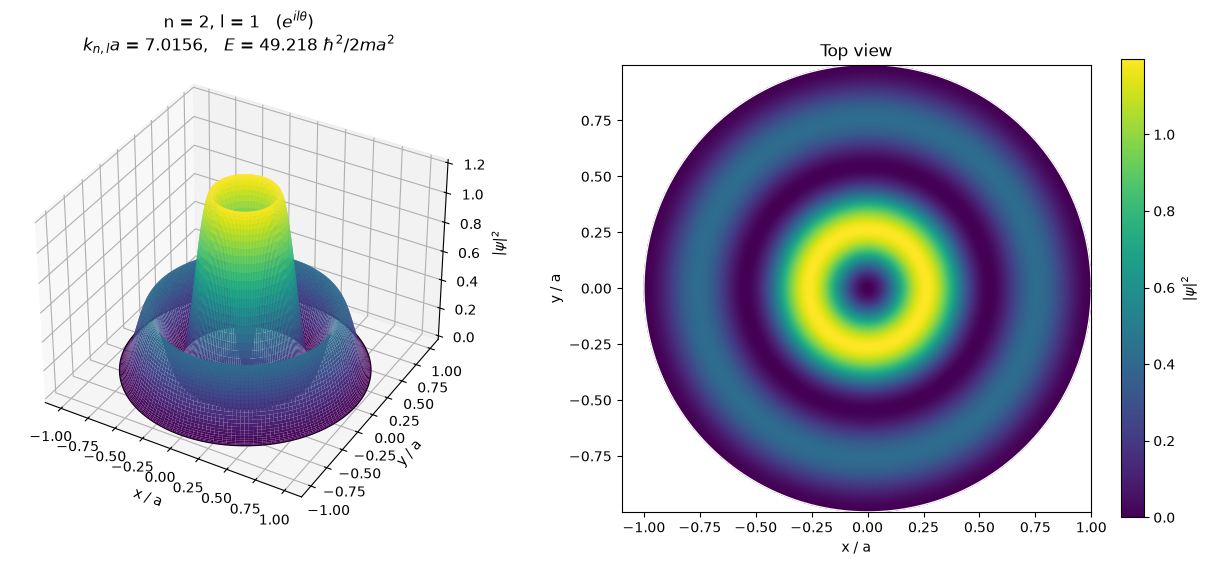

In [3]:
def plot_state(n=1, l=0, mode="exp", elev=35, azim=-60, show_2d=True):
    X, Y, P, j = prob_density(n, l, mode)
    E = j**2
    label = r"$e^{il\theta}$" if mode == "exp" else r"$\cos(l\theta)$"

    fig = plt.figure(figsize=(13, 5.5) if show_2d else (8, 6))
    ax = fig.add_subplot(1, 2 if show_2d else 1, 1, projection="3d")
    ax.plot_surface(X, Y, P, cmap=cm.viridis, rstride=1, cstride=1,
                    linewidth=0, antialiased=True)
    # draw the well wall
    th = np.linspace(0, 2*np.pi, 200)
    ax.plot(a*np.cos(th), a*np.sin(th), 0, "k-", lw=1)
    ax.set_xlabel("x / a"); ax.set_ylabel("y / a"); ax.set_zlabel(r"$|\psi|^2$")
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"n = {n}, l = {l}   ({label})\n"
                 rf"$k_{{n,l}}a$ = {j:.4f},   $E$ = {E:.3f} $\hbar^2/2ma^2$")

    if show_2d:
        ax2 = fig.add_subplot(1, 2, 2)
        c = ax2.pcolormesh(X, Y, P, cmap=cm.viridis, shading="gouraud")
        ax2.plot(a*np.cos(th), a*np.sin(th), "w-", lw=1)
        ax2.set_aspect("equal"); ax2.set_xlabel("x / a"); ax2.set_ylabel("y / a")
        ax2.set_title("Top view")
        fig.colorbar(c, ax=ax2, label=r"$|\psi|^2$")
    plt.tight_layout()
    plt.show()

plot_state(2, 1)

## Interactive explorer
Drag the slider to step through the states $(n, l)$ in order of energy (number of radial nodes = $n-1$, not counting the wall). Drag the 3D plot to rotate it; scroll to zoom. The first figure uses the $e^{il\theta}$ form, the second the $\cos(l\theta)$ form.

Built with Plotly (`conda install -c conda-forge plotly`), which renders in VS Code without needing ipywidgets.

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def explorer(mode="exp", n_max=5, l_max=6):
    # One slider step per (n, l), sorted by energy. Drag to rotate the 3D view.
    states = sorted(((n, l) for n in range(1, n_max+1) for l in range(l_max+1)),
                    key=lambda s: bessel_zero(*s))
    g = np.linspace(-a, a, 65)
    XX, YY = np.meshgrid(g, g)
    RR, TT = np.hypot(XX, YY), np.arctan2(YY, XX)

    fig = make_subplots(rows=1, cols=2, column_widths=[0.6, 0.4],
                        specs=[[{"type": "scene"}, {"type": "xy"}]],
                        subplot_titles=("", "Top view"))
    titles = []
    for i, (n, l) in enumerate(states):
        X, Y, P, j = prob_density(n, l, mode, Nr=45, Nt=73)
        # top view on a square grid, blank outside the well
        top = jv(l, j*RR/a)**2 / (np.pi*a**2*jv(l+1, j)**2)
        if mode == "cos" and l > 0:
            top = top * 2*np.cos(l*TT)**2
        top[RR > a] = np.nan
        vis = (i == 0)
        fig.add_trace(go.Surface(x=X.astype("f4"), y=Y.astype("f4"), z=P.astype("f4"),
                                 colorscale="Viridis", showscale=False, visible=vis),
                      row=1, col=1)
        fig.add_trace(go.Heatmap(x=g, y=g, z=top.astype("f4"), colorscale="Viridis",
                                 colorbar=dict(title="|ψ|²"), visible=vis),
                      row=1, col=2)
        titles.append(f"n = {n}, l = {l}   k·a = {j:.4f},   E = {j**2:.3f} ħ²/2ma²")

    th = np.linspace(0, 2*np.pi, 200)
    fig.add_trace(go.Scatter3d(x=a*np.cos(th), y=a*np.sin(th), z=0*th, mode="lines",
                               line=dict(color="black"), showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=a*np.cos(th), y=a*np.sin(th), mode="lines",
                             line=dict(color="white"), showlegend=False), row=1, col=2)

    steps = []
    for i, (n, l) in enumerate(states):
        vis = [False]*(2*len(states)) + [True, True]
        vis[2*i] = vis[2*i+1] = True
        steps.append(dict(method="update", label=f"{n},{l}",
                          args=[{"visible": vis}, {"title.text": titles[i]}]))
    label = "e^{ilθ}  (L_z eigenstate)" if mode == "exp" else "cos(lθ)  (standing wave)"
    fig.update_layout(
        title=titles[0], height=560,
        # 35 steps: small tick labels so they don't overlap; the readout above shows the state
        sliders=[dict(steps=steps, font=dict(size=8),
                      currentvalue=dict(prefix=f"{label}   (n, l) = ", font=dict(size=14)),
                      pad=dict(t=40))],
        scene=dict(xaxis_title="x / a", yaxis_title="y / a", zaxis_title="|ψ|²",
                   camera=dict(eye=dict(x=-1.2, y=-1.6, z=1.0))),
        margin=dict(l=10, r=10, t=60, b=10),
    )
    fig.update_xaxes(title="x / a", row=1, col=2)
    fig.update_yaxes(title="y / a", scaleanchor="x2", row=1, col=2)
    fig.show()

explorer("exp")

In [15]:
explorer("cos")

## Gallery of low-lying states
Rows: $n=1,2,3$. Columns: $l=0,1,2,3$. Shown in the $\cos(l\theta)$ form so the angular structure is visible.

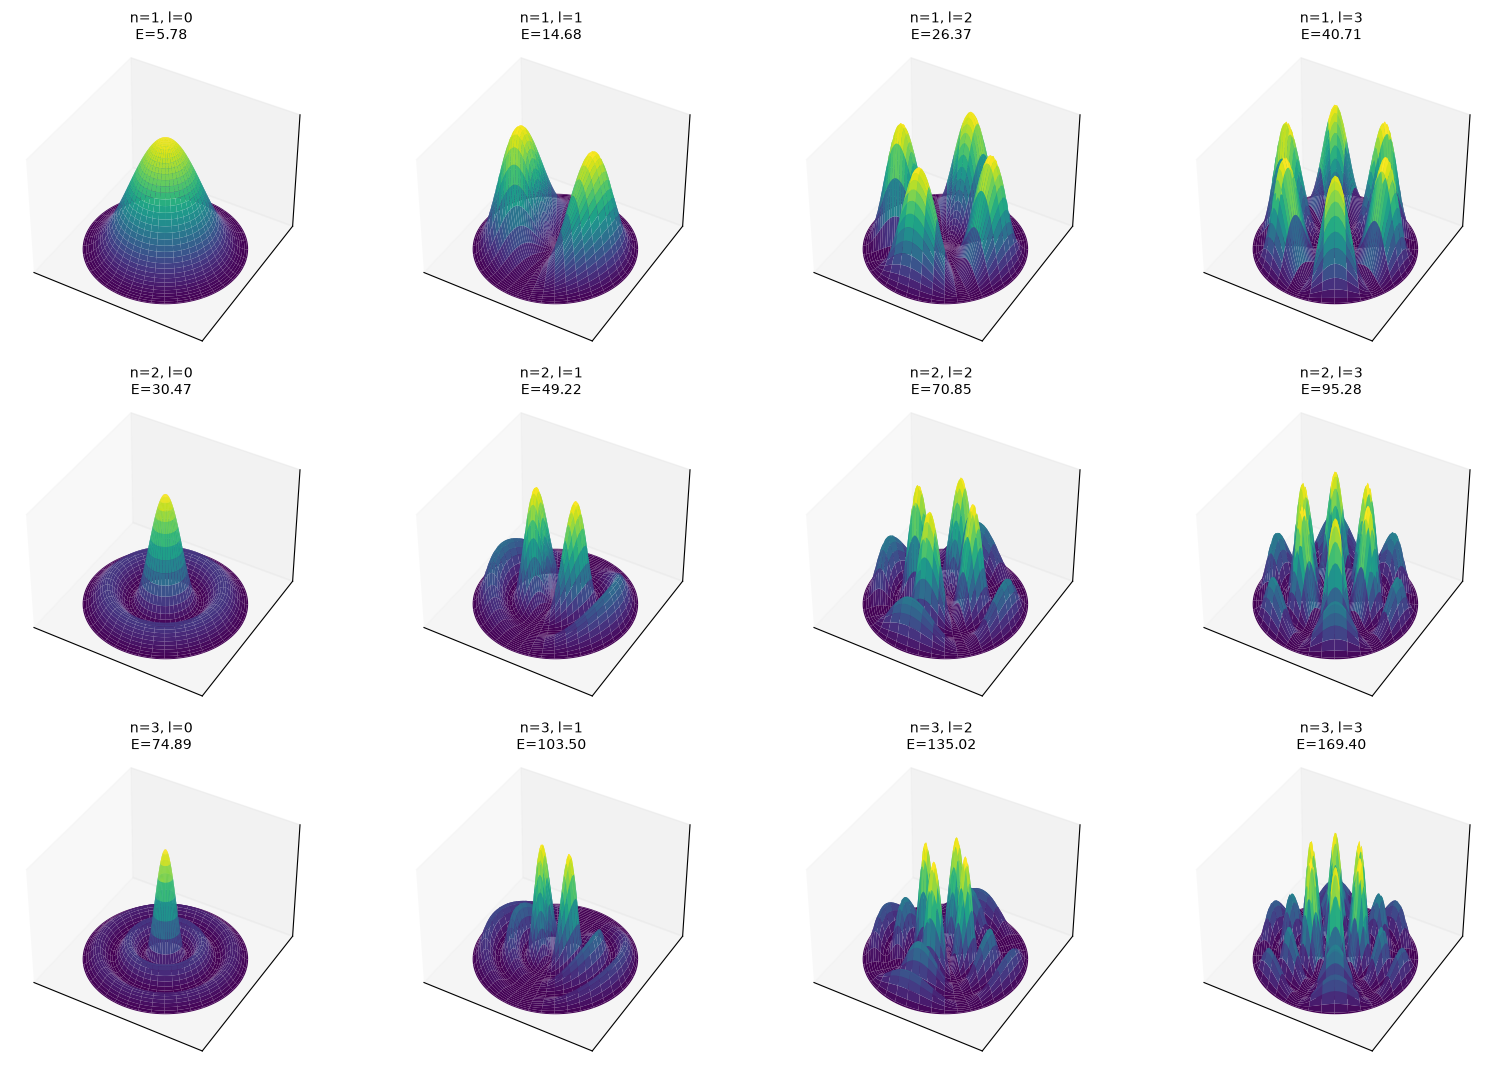

In [16]:
def gallery(n_max=3, l_max=3, mode="cos"):
    fig = plt.figure(figsize=(4*(l_max+1), 3.6*n_max))
    for n in range(1, n_max+1):
        for l in range(l_max+1):
            X, Y, P, j = prob_density(n, l, mode, Nr=70, Nt=120)
            ax = fig.add_subplot(n_max, l_max+1, (n-1)*(l_max+1) + l + 1,
                                 projection="3d")
            ax.plot_surface(X, Y, P, cmap=cm.viridis, linewidth=0)
            ax.set_title(f"n={n}, l={l}\nE={j**2:.2f}", fontsize=10)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
            ax.view_init(40, -60)
    plt.tight_layout(); plt.show()

gallery()

## Energy level diagram
Energies $E_{n,l}=j_{l,n}^2$ in units of $\hbar^2/(2ma^2)$. Every level with $l\neq0$ is doubly degenerate ($\pm l$).

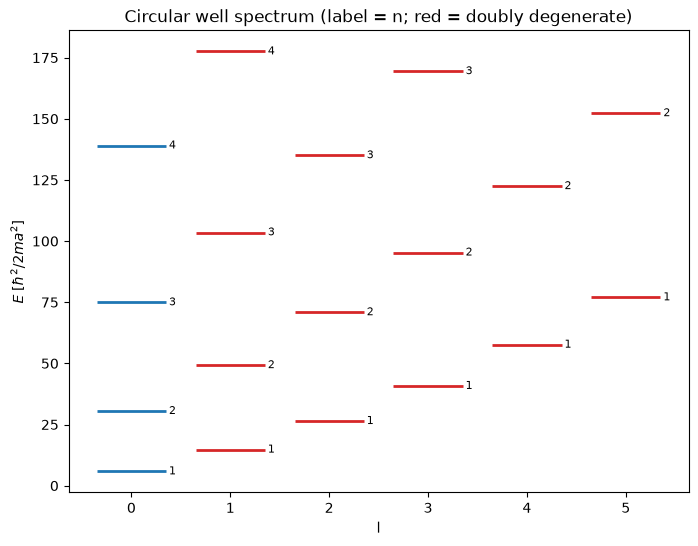

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
for l in range(0, 6):
    for n, j in enumerate(jn_zeros(l, 4), start=1):
        E = j**2
        if E > 200: continue
        ax.hlines(E, l-0.35, l+0.35, color="C0" if l == 0 else "C3", lw=2)
        ax.text(l+0.38, E, f"{n}", va="center", fontsize=8)
ax.set_xticks(range(6)); ax.set_xlabel("l")
ax.set_ylabel(r"$E\;[\hbar^2/2ma^2]$")
ax.set_title("Circular well spectrum (label = n; red = doubly degenerate)")
plt.show()